In [9]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats
import seaborn as sns


In [ ]:
#Getting the Average success values from the Rag and No Rag runs
df_cheap_norag1 = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_norag.csv')
df_cheap_rag1 = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_rag.csv')
df_cheap_norag2 = pd.read_csv('final_data/run2/vitis_oneshot_cheap_models_norag.csv')
df_cheap_rag2 = pd.read_csv('final_data/run2/vitis_oneshot_cheap_models_rag.csv')
df_expensive_norag1 = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_norag.csv')
df_expensive_rag1 = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_rag.csv')
df_expensive_norag2 = pd.read_csv('final_data/run2/vitis_oneshot_expensive_models_norag.csv')
df_expensive_rag2 = pd.read_csv('final_data/run2/vitis_oneshot_expensive_models_rag.csv')

# Cobining the different cheap and expensive dfs
df_rag1 = pd.concat([df_cheap_rag1, df_expensive_rag1], ignore_index=True)
df_rag2 = pd.concat([df_cheap_rag2, df_expensive_rag2], ignore_index=True)
df_norag1 = pd.concat([df_cheap_norag1, df_expensive_norag1], ignore_index=True)
df_norag2 = pd.concat([df_cheap_norag2, df_expensive_norag2], ignore_index=True)

# Formatting the successes and model names
df_rag1['latency'] = pd.to_numeric(df_rag1['latency'], errors='coerce')
df_rag1['Success'] = ((df_rag1['latency'].notna()) & (df_rag1['latency'] > 5)).astype(int)
df_rag1['model'] = df_rag1['model'].str.split('/').str[-1]

df_rag2['latency'] = pd.to_numeric(df_rag2['latency'], errors='coerce')
df_rag2['Success'] = ((df_rag2['latency'].notna()) & (df_rag2['latency'] > 5)).astype(int)
df_rag2['model'] = df_rag2['model'].str.split('/').str[-1]

df_norag1['latency'] = pd.to_numeric(df_norag1['latency'], errors='coerce')
df_norag1['Success'] = ((df_norag1['latency'].notna()) & (df_norag1['latency'] > 5)).astype(int)
df_norag1['model'] = df_norag1['model'].str.split('/').str[-1]

df_norag2['latency'] = pd.to_numeric(df_norag2['latency'], errors='coerce')
df_norag2['Success'] = ((df_norag2['latency'].notna()) & (df_norag2['latency'] > 5)).astype(int)
df_norag2['model'] = df_norag2['model'].str.split('/').str[-1]

#Getting success Rates
success_cnts_unsort = df_rag1.groupby('model')['Success'].sum()
success_counts = df_rag1.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rag1 = (success_counts / total_tests) * 100
success_rag1_unsort = (success_cnts_unsort / total_tests) * 100

success_cnts_unsort = df_rag2.groupby('model')['Success'].sum()
success_counts = df_rag2.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rag2 = (success_counts / total_tests) * 100
success_rag2_unsort = (success_cnts_unsort / total_tests) * 100

success_cnts_unsort = df_norag1.groupby('model')['Success'].sum()
success_counts = df_norag1.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_norag1 = (success_counts / total_tests) * 100
success_norag1_unsort = (success_cnts_unsort / total_tests) * 100

success_cnts_unsort = df_norag2.groupby('model')['Success'].sum()
success_counts = df_norag2.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_norag2 = (success_counts / total_tests) * 100
success_norag2_unsort = (success_cnts_unsort / total_tests) * 100

#Averaging the success rates
avg_success_rag = (success_rag1 + success_rag2) / 2
avg_success_norag = (success_norag1 + success_norag2) / 2
print(success_rag1)
print(success_rag2)
print(avg_success_rag)
# print(avg_success_norag)

#Get Average Price per Call in each Rag v NoRag run
model_costs_data_norag = {
    'Model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.11, 0.04, 0.84, 0.06, 0.13, 0.03, 2.44, 5.26, 3.83, 0.81]
}

costs_norag = pd.DataFrame(model_costs_data_norag).set_index('Model')
success_by_costs_norag = pd.DataFrame({
    'Success_Rate': avg_success_norag,
    'Cost': costs_norag['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values
# print(success_by_costs_norag)
model_costs_data_rag = {
    'Model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.22, 0.12, 0.92, 0.17, 0.18, 0.09, 2.93, 7.90, 6.13, 1.92]
}
costs_rag = pd.DataFrame(model_costs_data_rag).set_index('Model')
success_by_costs_rag = pd.DataFrame({
    'Success_Rate': model_costs_data_rag,
    'Cost': costs_rag['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values

model
deepseek-chat-v3-0324    50.990099
deepseek-r1-0528         72.277228
gemini-2.5-flash         73.267327
gemini-2.5-pro                 NaN
gpt-4.1-mini             76.237624
gpt-5                    90.594059
grok-4                         NaN
grok-code-fast-1         71.782178
Name: Success, dtype: float64


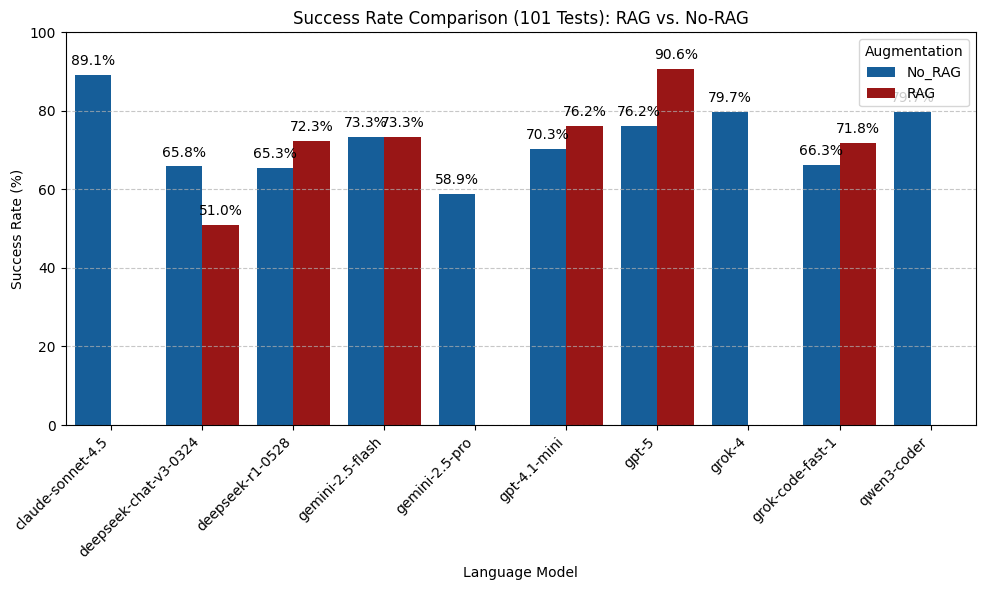

In [11]:
# Creating the Plots
# fig, axs = plt.subplots(1, 2, figsize=(18, 7))

df_plot = pd.DataFrame({
    'No_RAG': avg_success_norag,
    'RAG': avg_success_rag
})

# 2. Reformat the DataFrame for a grouped bar chart (using index as 'Model')
df_plot = df_plot.reset_index().rename(columns={'model': 'Model'})
df_plot_melted = df_plot.melt(
    id_vars='Model', 
    var_name='RAG_Status', 
    value_name='Success_Rate'
)

# Rename models for better display
model_names = {
    "openai/gpt-4.1-mini": "GPT-4.1 mini",
    "x-ai/grok-code-fast-1": "Grok Code Fast 1",
    "google/gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek/deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek/deepseek-r1-0528": "Deepseek R1",
    "qwen/qwen3-coder": "Qwen3 Coder",
    "x-ai/grok-4": "Grok 4",
    "google/gemini-2.5-pro": "Gemini 2.5 Pro"
}

df_plot_melted['Model'] = df_plot_melted['Model'].replace(model_names)

# --- Visualization ---

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Model', 
    y='Success_Rate', 
    hue='RAG_Status', 
    data=df_plot_melted, 
    palette=["#0060af", "#af0000"] # Blue for No RAG, Green for RAG
)

# Add title and labels
plt.title(f'Success Rate Comparison ({total_tests} Tests): RAG vs. No-RAG')
plt.ylabel('Success Rate (%)')
plt.xlabel('Language Model')
plt.ylim(0, 100) # Ensure the Y-axis goes up to 100%

# Add text labels on top of the bars
for p in plt.gca().patches:
    if p.get_height() > 0:
        plt.gca().annotate(f'{p.get_height():.1f}%', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', 
                       va='bottom',
                       fontsize=10,
                       color='black',
                       xytext=(0, 5), 
                       textcoords='offset points')

plt.legend(title='Augmentation')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


                       Success_Rate  Cost
claude-sonnet-4.5         89.108911  0.81
deepseek-chat-v3-0324     65.841584  0.04
deepseek-r1-0528          65.346535  0.84
gemini-2.5-flash          73.267327  0.11
gemini-2.5-pro            58.910891  3.83
gpt-4.1-mini              70.297030  0.06
gpt-5                     76.237624  2.44
grok-4                    79.702970  5.26
grok-code-fast-1          66.336634  0.13
qwen3-coder               79.702970  0.03


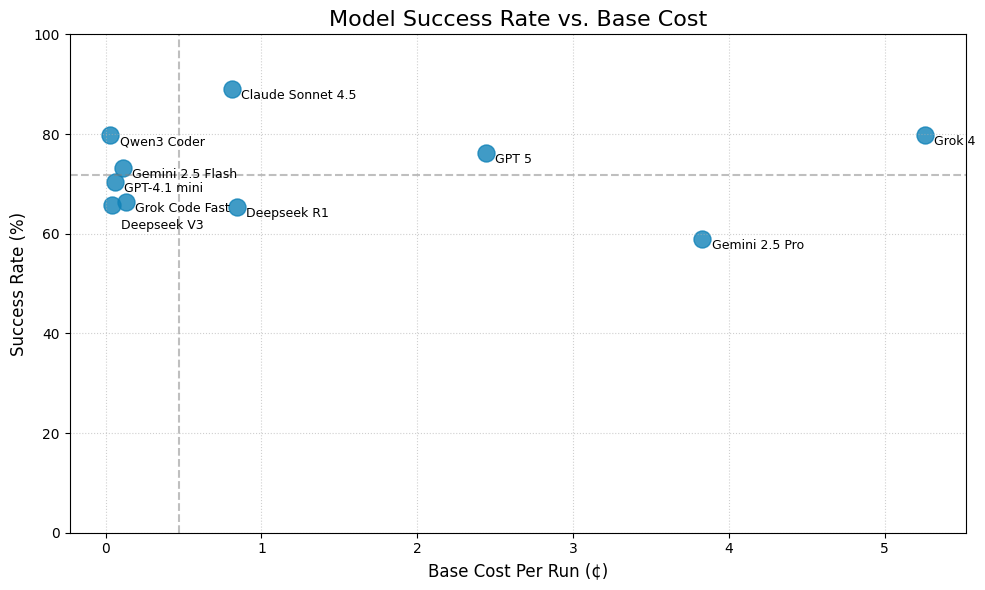

In [12]:
# Getting the updated cost per success model

# Create the scatter plot
plt.figure(figsize=(10, 6))

print(success_by_costs_norag)

plt.scatter(
    success_by_costs_norag['Cost'], 
    success_by_costs_norag['Success_Rate'], 
    s=150,  # Size of the points
    alpha=0.8,
    color="#1082b8"
)

# --- 3. Labeling and Formatting for Cost-Effectiveness ---
model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}

# Add model labels to the points
for model, row in success_by_costs_norag.iterrows():
    # Use model name as the label
    if model != "deepseek-chat-v3-0324":
        plt.annotate(
            model_names[model],
            (row['Cost'] + 0.06, row['Success_Rate']-2), # Offset label slightly to the right
            fontsize=9
        )
    else:
        plt.annotate(
            model_names[model],
            (row['Cost'] + 0.06, row['Success_Rate']-5), # Offset label slightly to the right
            fontsize=9
        )


median_cost = success_by_costs_norag['Cost'].median()
median_success = success_by_costs_norag['Success_Rate'].median()
# Horizontal Line (Median Success)
plt.axhline(median_success, color='gray', linestyle='--', alpha=0.5)
# Vertical Line (Median Cost)
plt.axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
plt.title('Model Success Rate vs. Base Cost', fontsize=16)
plt.xlabel('Base Cost Per Run (¢)', fontsize=12)
plt.ylabel('Success Rate (%)', fontsize=12)
plt.ylim(0,100)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
# plt.savefig('Model_Cost_Effectiveness_Scatter_Plot.png')
plt.show()


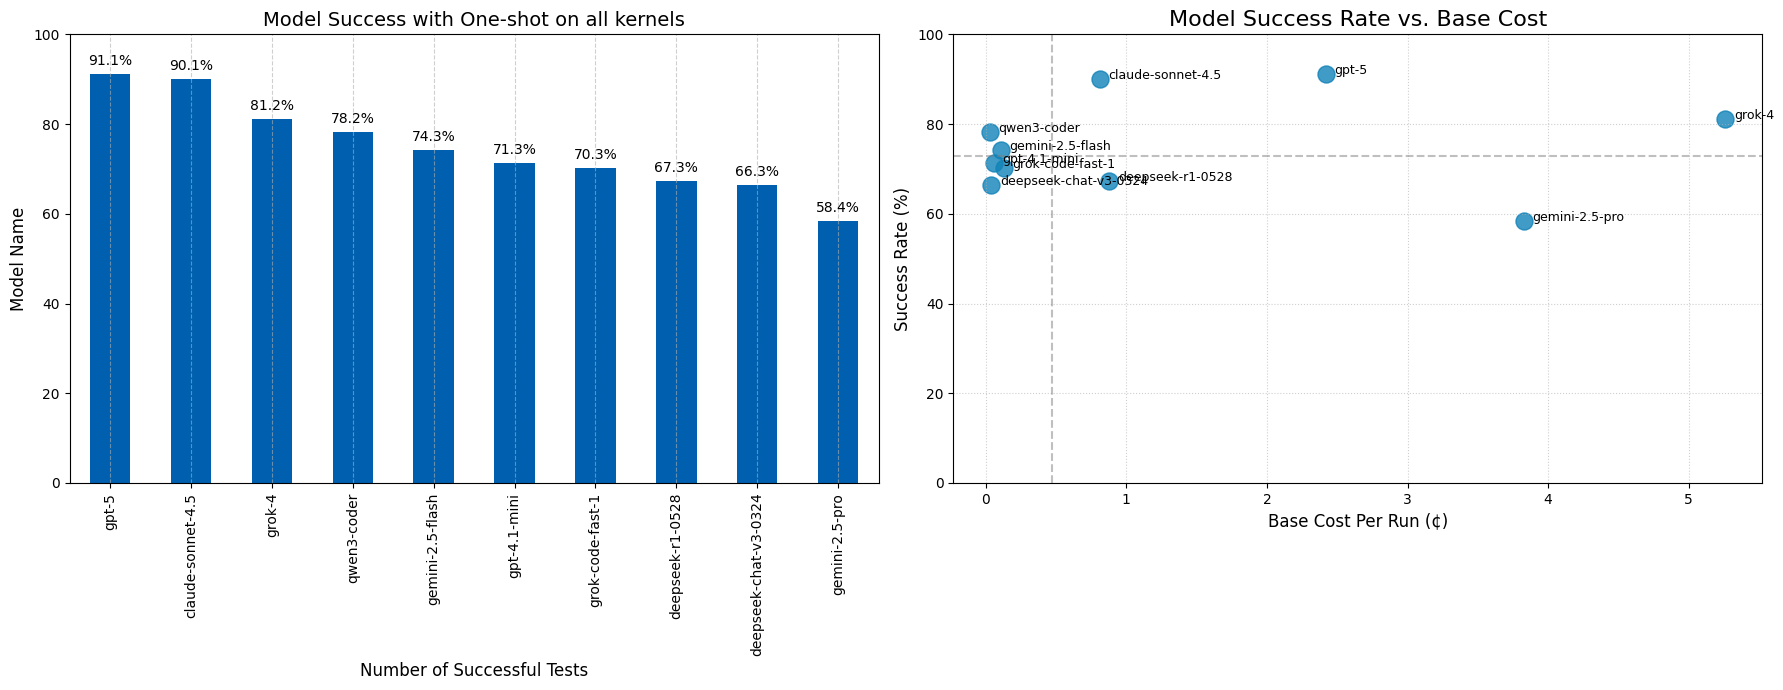

In [13]:
# Load data
df_oneshot_vitis_cheap = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_norag.csv')
df_oneshot_vitis_expensive = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_norag.csv')
# Calculate and add a column saying success for synthesis
df_oneshot_vitis_comb = pd.concat([df_oneshot_vitis_cheap, df_oneshot_vitis_expensive], ignore_index=True)
df_oneshot_vitis_comb['latency'] = pd.to_numeric(df_oneshot_vitis_comb['latency'], errors='coerce')
df_oneshot_vitis_comb['Success'] = ((df_oneshot_vitis_comb['latency'].notna()) & (df_oneshot_vitis_comb['latency'] > 5)).astype(int)
df_oneshot_vitis_comb['model'] = df_oneshot_vitis_comb['model'].str.split('/').str[-1]

# Calculate the Successes and Group by model
success_counts_unsorted = df_oneshot_vitis_comb.groupby('model')['Success'].sum()
success_counts = df_oneshot_vitis_comb.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag = (success_counts / total_tests) * 100
success_rates_unsorted = (success_counts_unsorted / total_tests) * 100

# print(success_rates_norag)

######################################## MAKE BAR CHART ###################################################
fig, axs = plt.subplots(1, 2, figsize=(18, 7))

# Generate the Bar chart
# plt.figure(figsize=(10,6))

success_rates_norag.plot(kind='bar', color="#0060af", ax=axs[0])
for index, value in enumerate(success_rates_norag):
    label = f"{value:.1f}%"
    axs[0].text(index, value+2, label, ha='center') # f' {value}' adds space after the bar
# Formatting and labels
axs[0].set_title(f'Model Success with One-shot on all kernels', fontsize=14)
axs[0].set_xlabel('Number of Successful Tests', fontsize=12)
axs[0].set_ylim(0,100)
axs[0].set_ylabel('Model Name', fontsize=12)
# Invert y-axis to put the highest performing model at the top
# axs[0].invert_yaxis() 
axs[0].grid(axis='x', linestyle='--', alpha=0.6) # Add light grid lines for readability
# plt.tight_layout()

#################################################### SCATTER PLOT CHART #################################################
model_costs_data = {
    'Model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.11, 0.04, 0.88, 0.06, 0.13, 0.03, 2.42, 5.26, 3.83, 0.81]
}

costs_df = pd.DataFrame(model_costs_data).set_index('Model')

combined_df = pd.DataFrame({
    'Success_Rate': success_rates_norag,
    'Cost': costs_df['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values

# --- 2. Generate the Scatter Plot ---

# Create the scatter plot
axs[1].scatter(
    combined_df['Cost'], 
    combined_df['Success_Rate'], 
    s=150,  # Size of the points
    alpha=0.8,
    color="#1082b8"
)

# --- 3. Labeling and Formatting for Cost-Effectiveness ---

# Add model labels to the points
for model, row in combined_df.iterrows():
    # Use model name as the label
    axs[1].annotate(
        model,
        (row['Cost'] + 0.06, row['Success_Rate']), # Offset label slightly to the right
        fontsize=9
    )


median_cost = combined_df['Cost'].median()
median_success = combined_df['Success_Rate'].median()
# Horizontal Line (Median Success)
axs[1].axhline(median_success, color='gray', linestyle='--', alpha=0.5)
# Vertical Line (Median Cost)
axs[1].axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
axs[1].set_title('Model Success Rate vs. Base Cost', fontsize=16)
axs[1].set_xlabel('Base Cost Per Run (¢)', fontsize=12)
axs[1].set_ylabel('Success Rate (%)', fontsize=12)
axs[1].set_ylim(0,100)
axs[1].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
# plt.savefig('Model_Cost_Effectiveness_Scatter_Plot.png')
plt.show()

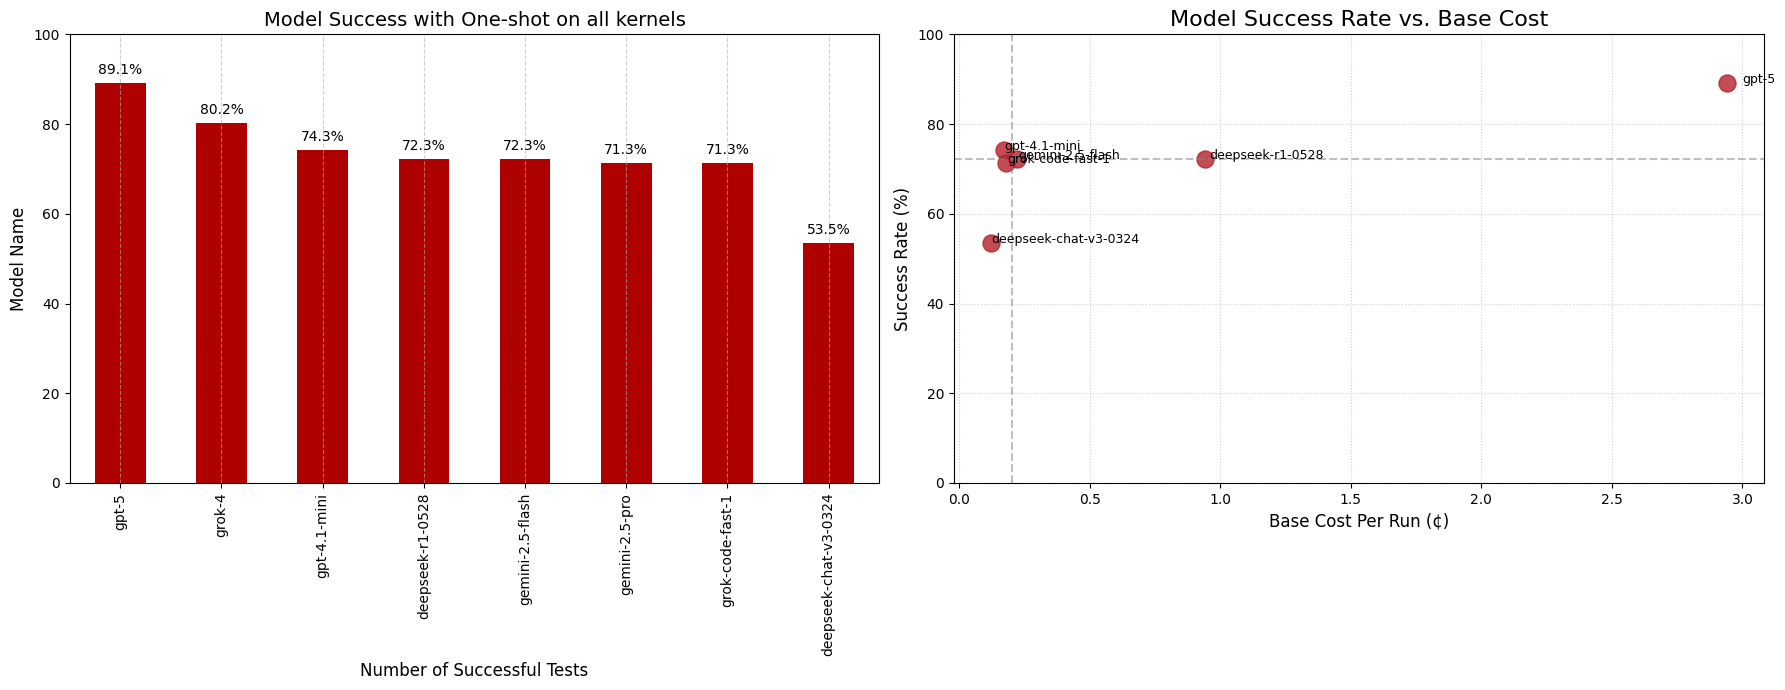

In [14]:
# Load data
df_oneshot_vitis_cheap = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_rag.csv')
df_oneshot_vitis_expensive = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_rag.csv')
# Calculate and add a column saying success for synthesis
df_oneshot_vitis_comb = pd.concat([df_oneshot_vitis_cheap, df_oneshot_vitis_expensive], ignore_index=True)
df_oneshot_vitis_comb['latency'] = pd.to_numeric(df_oneshot_vitis_comb['latency'], errors='coerce')
df_oneshot_vitis_comb['Success'] = ((df_oneshot_vitis_comb['latency'].notna()) & (df_oneshot_vitis_comb['latency'] > 5)).astype(int)
df_oneshot_vitis_comb['model'] = df_oneshot_vitis_comb['model'].str.split('/').str[-1]

# Calculate the Successes and Group by model
success_counts_unsorted = df_oneshot_vitis_comb.groupby('model')['Success'].sum()
success_counts = df_oneshot_vitis_comb.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_rag = (success_counts / total_tests) * 100
success_rates_unsorted = (success_counts_unsorted / total_tests) * 100

# print(success_rates_rag)

fig, axs = plt.subplots(1, 2, figsize=(18, 7))

# Generate the Bar chart
# plt.figure(figsize=(10,6))

success_rates_rag.plot(kind='bar', color="#af0000", ax=axs[0])
for index, value in enumerate(success_rates_rag):
    label = f"{value:.1f}%"
    axs[0].text(index, value+2, label, ha='center') # f' {value}' adds space after the bar
# Formatting and labels
axs[0].set_title(f'Model Success with One-shot on all kernels', fontsize=14)
axs[0].set_xlabel('Number of Successful Tests', fontsize=12)
axs[0].set_ylim(0,100)
axs[0].set_ylabel('Model Name', fontsize=12)
# Invert y-axis to put the highest performing model at the top
# axs[0].invert_yaxis() 
axs[0].grid(axis='x', linestyle='--', alpha=0.6) # Add light grid lines for readability
# plt.tight_layout()



# END OF BAR PLOT


model_costs_data = {
    'Model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'claude-sonnet-4.5'], # 'grok-4', 'gemini-2.5-pro', ],
    'Base_Cost_Per_Run': [0.22, 0.12, 0.94, 0.17, 0.18, 0.09, 2.94, 1.92]
}
costs_df = pd.DataFrame(model_costs_data).set_index('Model')

combined_df = pd.DataFrame({
    'Success_Rate': success_rates_rag,
    'Cost': costs_df['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values

# --- 2. Generate the Scatter Plot ---

# Create the scatter plot
axs[1].scatter(
    combined_df['Cost'], 
    combined_df['Success_Rate'], 
    s=150,  # Size of the points
    alpha=0.8,
    color="#b41f2b"
)

# --- 3. Labeling and Formatting for Cost-Effectiveness ---

# Add model labels to the points
for model, row in combined_df.iterrows():
    # Use model name as the label
    axs[1].annotate(
        model,
        (row['Cost'] * 1.02, row['Success_Rate']), # Offset label slightly to the right
        fontsize=9
    )


median_cost = combined_df['Cost'].median()
median_success = combined_df['Success_Rate'].median()
# Horizontal Line (Median Success)
axs[1].axhline(median_success, color='gray', linestyle='--', alpha=0.5)
# Vertical Line (Median Cost)
axs[1].axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
axs[1].set_title('Model Success Rate vs. Base Cost', fontsize=16)
axs[1].set_xlabel('Base Cost Per Run (¢)', fontsize=12)
axs[1].set_ylabel('Success Rate (%)', fontsize=12)
axs[1].set_ylim(0,100)
axs[1].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
# plt.savefig('Model_Cost_Effectiveness_Scatter_Plot.png')
plt.show()

In [15]:
# Combined Scatter Plot with Rag v No Rag
#Combine the two scatter plots

combined_norag_df['Group'] = "norag"
combined_rag_df['Group'] = "rag"

combined_df = pd.concat([combined_norag_df, combined_rag_df], ignore_index=False)
# print(combined_df)
# --- Generate the Overlapped Scatter Plot ---
plt.figure(figsize=(12, 8))

# Define colors for the groups
colors = {'rag': '#af0000', 'norag': 'steelblue'}

# Plot each group separately to assign different colors and labels
for name, group in combined_df.groupby('Group'):
    plt.scatter(
        group['Cost'],
        group['Success_Rate'],
        s=200,  # Size of the points
        alpha=0.8,
        color=colors[name],
        label=name # Label for the legend
    )

# Add model labels to the points
for model, row in combined_df.iterrows():
    plt.annotate(
        model,
        (row['Cost'] + 0.06, row['Success_Rate']), # Offset label slightly
        fontsize=9
    )
# Add median lines
median_cost = combined_df['Cost'].median()
median_success = combined_df['Success_Rate'].median()
plt.axhline(median_success, color='gray', linestyle='--', alpha=0.5)
plt.axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
plt.title('Model Success Rate vs. Base Cost (Combined)', fontsize=16)
plt.xlabel('Base Cost Per Run (¢)', fontsize=12)
plt.ylabel('Success Rate (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title="Model Group") # Show legend to differentiate groups
plt.tight_layout()

plt.show()


NameError: name 'combined_norag_df' is not defined

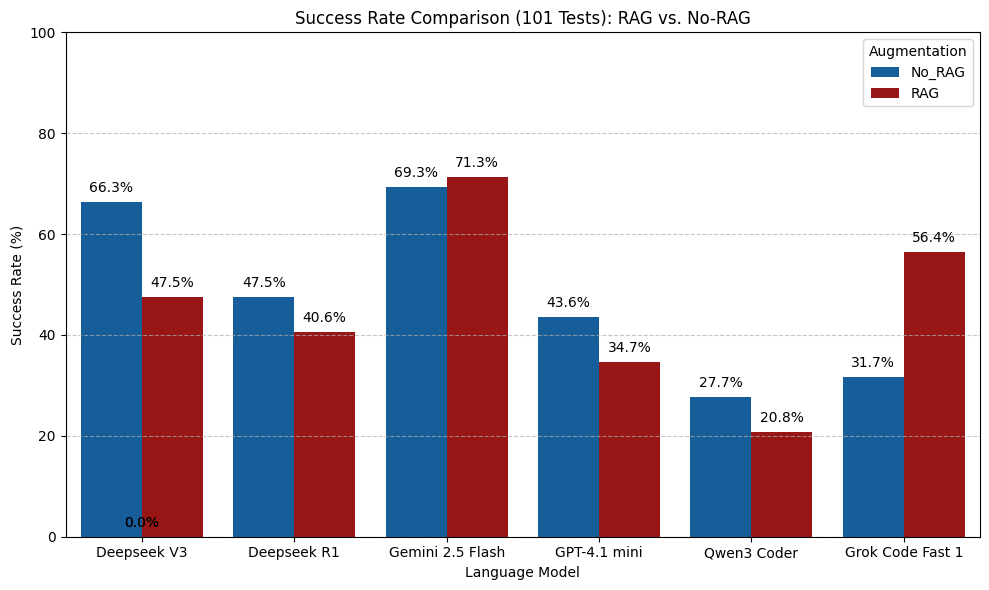

In [ ]:
#COmparing the RAG success to No RAG

df_cheap_rag = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_rag.csv')
df_cheap_norag = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_norag.csv')

df_claude_gpt5_norag = df_cheap_norag[df_cheap_norag['model'].isin({"openai/gpt-4.1-mini","x-ai/grok-code-fast-1","google/gemini-2.5-flash","deepseek/deepseek-chat-v3-0324","deepseek/deepseek-r1-0528","qwen/qwen3-coder"})].copy()
df_claude_gpt5_norag.loc[:, 'israg'] = False
# print(df_claude_gpt5)
df_claude_gpt5_rag = df_cheap_rag[df_cheap_rag['model'].isin({"openai/gpt-4.1-mini","x-ai/grok-code-fast-1","google/gemini-2.5-flash","deepseek/deepseek-chat-v3-0324","deepseek/deepseek-r1-0528","qwen/qwen3-coder"})].copy()
df_claude_gpt5_rag.loc[:, 'israg'] = True
# print(df_claude_gpt5_rag)

df_claude_gpt5_norag['latency'] = pd.to_numeric(df_claude_gpt5_norag['latency'], errors='coerce')
df_claude_gpt5_norag['Success'] = ((df_claude_gpt5_norag['latency'].notna()) & (df_claude_gpt5_norag['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_claude_gpt5_norag.groupby('model')['Success'].sum()
success_counts = df_claude_gpt5_norag.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag = (success_counts / total_tests) * 100
success_rates_unsorted_norag = (success_counts_unsorted / total_tests) * 100

df_claude_gpt5_rag['latency'] = pd.to_numeric(df_claude_gpt5_rag['latency'], errors='coerce')
df_claude_gpt5_rag['Success'] = ((df_claude_gpt5_rag['latency'].notna()) & (df_claude_gpt5_rag['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_claude_gpt5_rag.groupby('model')['Success'].sum()
success_counts = df_claude_gpt5_rag.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_rag = (success_counts / total_tests) * 100
success_rates_unsorted_rag = (success_counts_unsorted / total_tests) * 100

df_plot = pd.DataFrame({
    'No_RAG': success_rates_norag,
    'RAG': success_rates_rag
})

# 2. Reformat the DataFrame for a grouped bar chart (using index as 'Model')
df_plot = df_plot.reset_index().rename(columns={'model': 'Model'})
df_plot_melted = df_plot.melt(
    id_vars='Model', 
    var_name='RAG_Status', 
    value_name='Success_Rate'
)

# Rename models for better display
model_names = {
    "openai/gpt-4.1-mini": "GPT-4.1 mini",
    "x-ai/grok-code-fast-1": "Grok Code Fast 1",
    "google/gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek/deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek/deepseek-r1-0528": "Deepseek R1",
    "qwen/qwen3-coder": "Qwen3 Coder"
}

df_plot_melted['Model'] = df_plot_melted['Model'].replace(model_names)

# --- Visualization ---

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Model', 
    y='Success_Rate', 
    hue='RAG_Status', 
    data=df_plot_melted, 
    palette=["#0060af", "#af0000"] # Blue for No RAG, Green for RAG
)

# Add title and labels
plt.title(f'Success Rate Comparison ({total_tests} Tests): RAG vs. No-RAG')
plt.ylabel('Success Rate (%)')
plt.xlabel('Language Model')
plt.ylim(0, 100) # Ensure the Y-axis goes up to 100%

# Add text labels on top of the bars
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():.1f}%', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', 
                       va='bottom',
                       fontsize=10,
                       color='black',
                       xytext=(0, 5), 
                       textcoords='offset points')

plt.legend(title='Augmentation')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
